In [1]:
import numpy as np
import torch
np.random.seed(42)
torch.manual_seed(42)
ydata=np.load("ydata.npy")
sp9=np.load("sp.npy")

def normalize(x,x_max,x_min):
    # if x_max==x_min:
    #     return np.zeros_like(x)
    return (x-x_min)/(x_max-x_min)*2-1

def denormalize(x,x_max,x_min):
    drange=x_max-x_min
    return (x+1)/2*drange+x_min

spmax=sp9.max(axis=1)
spmin=sp9.min(axis=1)

sp_n=normalize(sp9,spmax[:,np.newaxis],spmin[:,np.newaxis])
spmax_max=spmax.max()
spmax_min=spmax.min()
spmin_max=spmin.max()
spmin_min=spmin.min()

spmax_n=normalize(spmax,spmax_max,spmax_min)
spmin_n=normalize(spmin,spmin_max,spmin_min)

embdata=np.concatenate((sp_n,spmax_n[:,np.newaxis],spmin_n[:,np.newaxis]),axis=1)
ydata_norm=normalize(ydata,spmax.reshape(-1,1,1),spmin.reshape(-1,1,1))

array=np.arange(0,ydata_norm.shape[0])
index=np.random.choice(array,10000,replace=False)

v_ydata=ydata_norm[index]
v_emb=embdata[index]
t_ydata=np.delete(ydata_norm,index,0)
t_emb=np.delete(embdata,index,0)

In [2]:
ydata.shape

(93340, 40, 240)

In [5]:
from torch.utils.data import Dataset,DataLoader
class MyDataset(Dataset):
    def __init__(self,embdata,ydata):
        self.embdata=embdata
        self.ydata=ydata
    def __len__(self):
        return len(self.embdata)
    def __getitem__(self,idx):
        return self.embdata[idx],self.ydata[idx]

train_dataset=MyDataset(t_emb,t_ydata)
val_dataset=MyDataset(v_emb,v_ydata)
train_loader=DataLoader(train_dataset,batch_size=32)
val_loader=DataLoader(val_dataset,batch_size=50)

In [6]:
import torch.nn as nn

class MLPNet(nn.Module):
    def __init__(self, input_dim=11, output_dim=9600):
        super(MLPNet, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(256, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(1024, 4096),
            nn.BatchNorm1d(4096),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(4096, output_dim)
        )

    def forward(self, x):
        return self.network(x)

In [7]:
from tqdm import tqdm

device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model=MLPNet().to(device)
model.load_state_dict(torch.load("mlp_sp9.pth",map_location=device))
model.eval()

# for xb,yb in val_loader:
#     break

# with torch.no_grad():
#     y_pred=model(xb.to(device))

# criterion=nn.MSELoss()
# optimizer=torch.optim.Adam(model.parameters(),lr=0.001)
# epochs=250
# losslist=[]

# for epoch in tqdm(range(epochs)):
#     model.train()
#     total_loss=0.
#     for xb,yb in train_loader:
#         optimizer.zero_grad()
#         y_pred=model(xb.to(device))
#         loss=criterion(y_pred,yb.reshape(-1,9600).to(device))
#         loss.backward()
#         optimizer.step()
#         total_loss+=loss.item()
#     avg_loss=total_loss/len(train_loader)
#     losslist.append(avg_loss)

# from matplotlib import pyplot as plt
# plt.plot(losslist)

MLPNet(
  (network): Sequential(
    (0): Linear(in_features=11, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=256, out_features=1024, bias=True)
    (9): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=1024, out_features=4096, bias=True)
    (13): BatchNorm1d(4096, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (14): ReLU()
    (15): Dropout(p=0.2, inplace=False)
    (16): Linear(in_features=4096, out_features=9600, bias=True)
  )
)

In [8]:
# maxval,minval=denormalize(xb[0][5],spmax_max,spmax_min),denormalize(xb[0][6],spmin_max,spmin_min)
# out_val=denormalize(out[0].reshape(40,240),maxval.numpy(),minval.numpy())
# ture=denormalize(yb[0],maxval.numpy(),minval.numpy())

In [9]:
y_true=np.empty((0,40,240))
y_pred=np.empty((0,40,240))
x_in=np.empty((0,11))
for veb,vyb in tqdm(val_loader):
    x_in=np.concatenate((x_in,veb.numpy()),axis=0)
    y_true=np.concatenate((y_true,vyb.numpy()),axis=0)
    veb=veb.to(device)
    # vyb=vyb.unsqueeze(1).to(device)
    sample=model(veb)
    y_pred=np.concatenate((y_pred,sample.reshape(-1,40,240).cpu().detach().numpy()),axis=0)
    break

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]


In [10]:
spmax_vector=denormalize(x_in[:,9],spmax_max,spmax_min).reshape(-1,1,1)
spmin_vector=denormalize(x_in[:,10],spmin_max,spmin_min).reshape(-1,1,1)
true=denormalize(y_true,spmax_vector,spmin_vector)
pred=denormalize(y_pred,spmax_vector,spmin_vector)

In [11]:
def calculate_rmse(matrix1, matrix2):
    error = matrix1 - matrix2    
    # 计算均方误差 (MSE)
    mse = np.mean(error ** 2)    
    # 计算均方根误差 (RMSE)
    rmse = np.sqrt(mse)    
    return rmse
mlp_rmse=[]
for i in range(true.shape[0]):
    rmse=calculate_rmse(true[i],pred[i])
    mlp_rmse.append(rmse)

# np.save('mlp_rmse.npy',np.array(mlp_rmse))

In [14]:
true[-1],pred[-1]

(array([[301.52920565, 301.52914464, 301.52908362, ..., 300.278229  ,
         300.26766992, 300.25711084],
        [301.53747596, 301.53744541, 301.53735385, ..., 300.31597927,
         300.30566429, 300.29531885],
        [301.54550204, 301.54547157, 301.54538001, ..., 300.35293603,
         300.34289575, 300.33279442],
        ...,
        [301.67736859, 301.67733795, 301.67730749, ..., 301.10858182,
         301.1037906 , 301.09896883],
        [301.67724639, 301.67721592, 301.67718545, ..., 301.11312898,
         301.10836823, 301.10360747],
        [301.67691076, 301.67691076, 301.67684974, ..., 301.11663854,
         301.11193879, 301.10717804]], shape=(40, 240)),
 array([[301.50700287, 301.50696373, 301.50688359, ..., 300.28530963,
         300.27510814, 300.26482338],
        [301.51416229, 301.5141295 , 301.51405202, ..., 300.31774699,
         300.30763681, 300.29753717],
        [301.52112736, 301.52108166, 301.52099826, ..., 300.34911586,
         300.33920032, 300.3291836

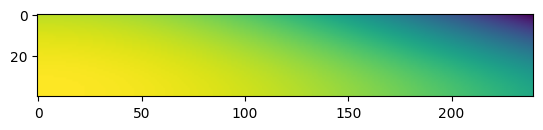

In [13]:
import matplotlib.pyplot as plt
plt.imshow(true[-1])

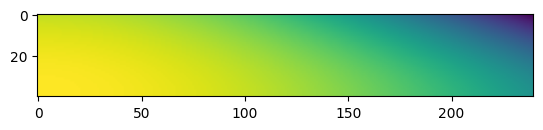

In [15]:
plt.imshow(pred[-1])

In [16]:
np.save('mlp-1.npy',pred[-1])